# Noise PSDs from the `clean_randoms` cut: series 07221203_2025, dump F0001

The cut developed in the note is the cut of Notes 2 and 2a made on `Side1pB` (Detector 1 / Channel 1): a random trigger in the Tight excursion band of a 500-sample pretrigger window with `log10(bstd) < 0.5`. It keeps 101 of the 1008 randoms, none of which has a pulse or a big tail in any channel (section 10 and 11 of `chan0-cut-on-all-channels-buddy.ipynb`, where the cut is defined as `clean_randoms`).

This notebook uses those same 101 events, **the same events for every channel**, to compute the noise power spectral density (PSD) of each of the 12 channels. A dead channel (its signal never changes) has no spectrum and is skipped.

The PSD is the one-sided estimate of the note: for a baseline-subtracted trace of N samples taken every Δt, with Fourier transform X[k],

    S[k] = (2 Δt / N) · mean over the traces of |X[k]|²        (counts² / Hz)

with the factor 2 left out for the zero-frequency and Nyquist bins.

**Caveats.** `pulse_cuts.randoms` assumes the dump's trigger-type labels are swapped (Note 2a); the channel names are provisional (`pulse_channels`); and `Side2pB` may not be a normal phonon channel (see the Caveats of the note). Run with the `darkmatter_cli_env` kernel.

*Author: buddy. Draft.*

In [1]:
import sys
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))

import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_quantities as pq
import pulse_operations as po
import pulse_cuts as pc
import pulse_channels as pch
from pulse_config import PulseConfig

import check_environment
check_environment.check()

def short_label(det, ch):
    """Channel name with its readout board, e.g. 'Side2pC (DCRC1)'."""
    return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


## 1. Load the dump and apply the cut

`clean_randoms_cut` is the cut of the note, written once. It is evaluated on `Side1pB` only, and the resulting event list is used for every channel.

In [2]:
DUMP = "07221203_2025_F0001"
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10, sample_period_s=1.6e-6)
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
det_ids = {det: pio.filter_by_detector(cdms.get_detector_ids(), det) for det in range(3)}
KEYS = [(det, ch) for det in range(3) for ch in range(4)]

# The three boards share their events, in the same order, so one event list serves every channel.
event_numbers = np.array([int(pio.event_id(i)) for i in det_ids[0]])
for det in (1, 2):
    assert np.array_equal(event_numbers, [int(pio.event_id(i)) for i in det_ids[det]])

CLEAN_KEY = (1, 1)        # Side1pB (DCRC3), the channel the cut is made on

def clean_randoms_cut(pulses, trigger_types, config=config_500):
    """Randoms with no pulse: the Note 2 / 2a cut (Tight excursion band and log10(bstd) < 0.5) on one channel."""
    with np.errstate(all="ignore"):
        quiet = pc.excursion_band(pulses, config) & (np.log10(pq.bstd(pulses, config)) < 0.5)
    return pc.randoms(trigger_types) & quiet

_, p_clean = pio.load_channel_batch(cdms, det_ids[CLEAN_KEY[0]], CLEAN_KEY[1])
clean_randoms = clean_randoms_cut(p_clean, pio.trigger_types(cdms, det_ids[CLEAN_KEY[0]]))   # <- the cut of the note
print(f"{len(event_numbers)} events; clean_randoms on {short_label(*CLEAN_KEY)}: {clean_randoms.sum()} events")

1517 events; clean_randoms on Side1pB (DCRC3): 101 events


C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\1380629641.py:18: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  return pc.randoms(trigger_types) & quiet
C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\2069116818.py:25: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\Research\NSDF-Data\python\pulse_channels.py:83: UserWarning: channel_info is marked under_development: the

## 2. One-sided PSD of every channel

Each trace is baseline-subtracted (the mean of the 500-sample pretrigger window, skipping the first 10 samples) and the 10 leading glitch samples are dropped, then Fourier transformed. A channel is **dead** if its traces never change (zero scatter in every trace).

In [3]:
def processed(pulse_array):
    # baseline-subtract (500-sample window) and drop the leading glitch samples
    return po.trim_glitch(po.baseline_subtract(pulse_array, config_500), config_500)

def one_sided_psd(traces, config=config_500):
    """One-sided PSD (counts^2/Hz) of each trace: (2 dt / N) |X[k]|^2, without the factor 2 at DC and Nyquist."""
    n = traces.shape[-1]
    psd = pq.power_spectrum(traces, config) * (config.sample_period_s / n)
    psd[..., 1:(n + 1) // 2 if n % 2 else n // 2] *= 2          # all bins that have a mirror at negative frequency
    return psd

n_samples = processed(p_clean[:1]).shape[-1]
freqs = pq.frequencies_hz(n_samples, config_500)
psd = {}                    # (det, ch) -> PSD of every selected trace, shape (events, bins)
dead = []
for key in KEYS:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    if np.all(p.std(axis=1) == 0):
        dead.append(key)
        continue
    psd[key] = one_sided_psd(processed(p[clean_randoms]))
working = list(psd)
print(f"{len(working)} working channels, {len(dead)} dead: {', '.join(short_label(*k) for k in dead)}")
print(f"{n_samples} samples per trace after the glitch, {len(freqs)} frequency bins from {freqs[1]:.0f} Hz to {freqs[-1]/1e3:.0f} kHz")

# Check of the normalisation (Parseval): the integral of the PSD over frequency is the mean square of the trace
# (its variance if the trace had zero mean over the whole window; the baseline is only the 500-sample pretrigger mean)
key = working[0]
_, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
tr = processed(p[clean_randoms])
var_psd = (psd[key].sum(axis=1) * (freqs[1] - freqs[0]))
print(f"{short_label(*key)}: mean square of the traces {(tr ** 2).mean(axis=1).mean():.3f} counts^2, integral of the PSD {var_psd.mean():.3f} counts^2")

7 working channels, 5 dead: Side1pC (DCRC1), Side1pD (DCRC3), Side2pA (DCRC4), Side1pA (DCRC4), Side2pD (DCRC4)
4086 samples per trace after the glitch, 2044 frequency bins from 153 Hz to 312 kHz
Side2pC (DCRC1): mean square of the traces 4.580 counts^2, integral of the PSD 4.580 counts^2


C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\2069116818.py:25: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\2069116818.py:25: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"


## 3. A table of the spectra

For each working channel, the mean PSD (over the 101 traces) in three bands and the white-noise floor as an amplitude density, the square root of the PSD above 100 kHz.

In [4]:
bands = [("1-10 kHz", 1e3, 1e4), ("10-100 kHz", 1e4, 1e5), (">100 kHz", 1e5, np.inf)]
print(f"{'channel':<20}{'traces':>7}" + "".join(f"{name:>13}" for name, _, _ in bands) + f"{'floor (counts/rtHz)':>22}")
for key in working:
    mean = psd[key].mean(axis=0)
    vals = [mean[(freqs >= lo) & (freqs < hi)].mean() for _, lo, hi in bands]
    print(f"{short_label(*key):<20}{psd[key].shape[0]:>7}" + "".join(f"{v:>13.2e}" for v in vals) + f"{np.sqrt(vals[2]):>22.2e}")

channel              traces     1-10 kHz   10-100 kHz     >100 kHz   floor (counts/rtHz)
Side2pC (DCRC1)         101     4.51e-05     7.47e-06     5.63e-06              2.37e-03
Side2pF (DCRC1)         101     6.81e-05     9.09e-06     5.90e-06              2.43e-03
Side1pF (DCRC1)         101     5.43e-05     8.13e-06     5.92e-06              2.43e-03
Side1pE (DCRC3)         101     8.41e-05     2.97e-05     1.33e-05              3.65e-03
Side1pB (DCRC3)         101     1.51e-04     3.32e-05     6.70e-06              2.59e-03
Side2pE (DCRC3)         101     1.08e-04     2.37e-05     1.66e-05              4.07e-03
Side2pB (DCRC4)         101     6.82e-06     6.47e-06     6.04e-06              2.46e-03


C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\2069116818.py:25: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\2069116818.py:25: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"


## 4. The spectra by side

Side 1 on the left and Side 2 on the right, one colour per channel within each panel (the colours are not shared between the panels). Each curve is the mean PSD over the 101 traces. The shaded band is the 16th to 84th percentile of the individual traces' PSDs, found separately at every frequency bin.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\1920995916.py:4: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  keys = [k for k in working if pch.channel_info(*k).side == side]


C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\2069116818.py:25: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\2069116818.py:25: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"


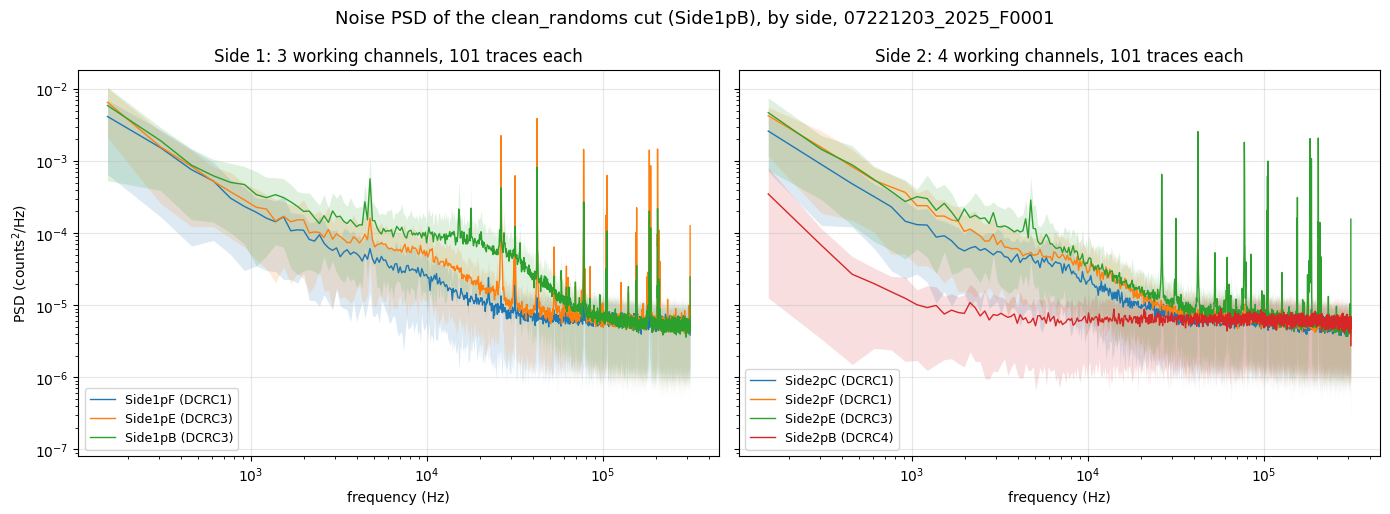

In [5]:
side_colour_index = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)
for ax, side in zip(axes, (1, 2)):
    keys = [k for k in working if pch.channel_info(*k).side == side]
    for i, key in enumerate(keys):
        lo, hi = np.percentile(psd[key], [16, 84], axis=0)
        colour = f"C{i}"
        ax.fill_between(freqs[1:], lo[1:], hi[1:], color=colour, alpha=0.15, linewidth=0)
        ax.loglog(freqs[1:], psd[key].mean(axis=0)[1:], linewidth=1.0, color=colour, label=short_label(*key))
    ax.set_title(f"Side {side}: {len(keys)} working channels, {int(clean_randoms.sum())} traces each")
    ax.set_xlabel("frequency (Hz)")
    ax.grid(True, which="major", alpha=0.3)
    ax.legend(fontsize=9)
axes[0].set_ylabel("PSD (counts$^2$/Hz)")
fig.suptitle(f"Noise PSD of the clean_randoms cut (Side1pB), by side, {DUMP}", fontsize=13)
fig.tight_layout()
plt.savefig(f"figures/psd-clean-randoms-by-side-{DUMP}.png", dpi=110)
plt.show()

## 5. The spectrum of every channel, one tile each

The same spectra as 12 tiles (rows are the boards DCRC1, DCRC3, DCRC4 and columns the four channels of each board), all on the same axes, with the 16th to 84th percentile band as above. A dead channel has an empty tile.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\2158552903.py:6: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  c = pch.channel_info(det, ch)


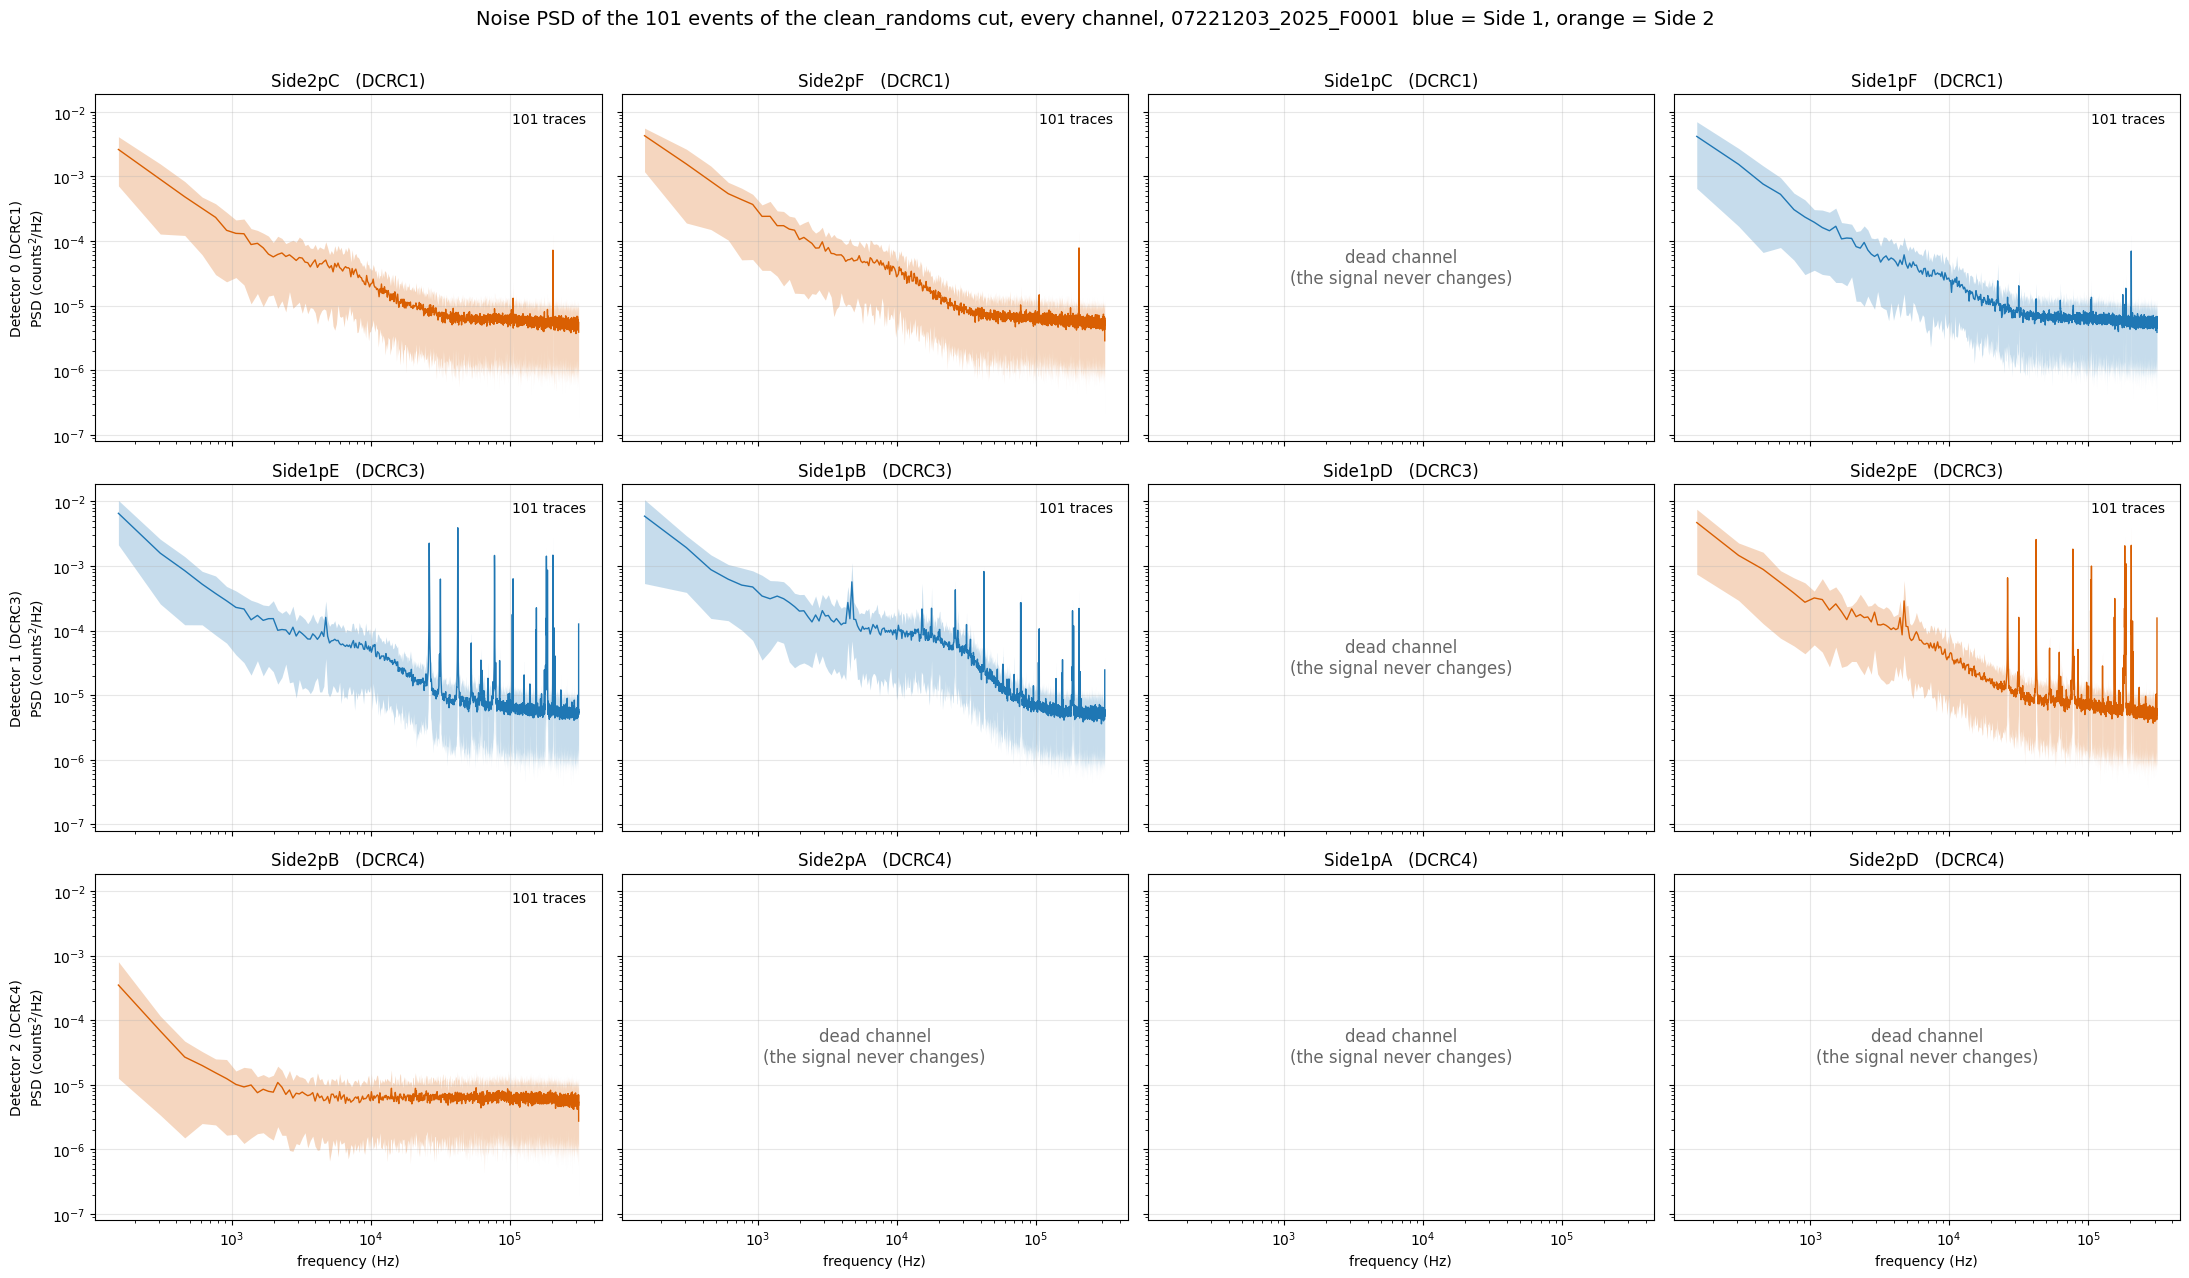

In [6]:
side_colour = {1: "#1f77b4", 2: "#d95f02"}
fig, axes = plt.subplots(3, 4, figsize=(22, 13), sharex=True, sharey=True)
for key in KEYS:
    det, ch = key
    ax = axes[det, ch]
    c = pch.channel_info(det, ch)
    ax.set_title(f"{c.name}   ({c.dcrc})", fontsize=12)
    if key in dead:
        ax.text(0.5, 0.5, "dead channel" + chr(10) + "(the signal never changes)", transform=ax.transAxes,
                ha="center", va="center", color="0.4", fontsize=12)
    else:
        lo, hi = np.percentile(psd[key], [16, 84], axis=0)
        ax.fill_between(freqs[1:], lo[1:], hi[1:], color=side_colour[c.side], alpha=0.25, linewidth=0)
        ax.plot(freqs[1:], psd[key].mean(axis=0)[1:], color=side_colour[c.side], linewidth=1.0)
        ax.text(0.97, 0.95, f"{psd[key].shape[0]} traces", transform=ax.transAxes, ha="right", va="top", fontsize=10)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(True, which="major", alpha=0.3)
    if ch == 0:
        ax.set_ylabel(f"Detector {det} ({c.dcrc})" + chr(10) + "PSD (counts$^2$/Hz)")
    if det == 2:
        ax.set_xlabel("frequency (Hz)")
fig.suptitle(f"Noise PSD of the {int(clean_randoms.sum())} events of the clean_randoms cut, every channel, {DUMP}"
             "  blue = Side 1, orange = Side 2", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig(f"figures/psd-clean-randoms-tiles-{DUMP}.png", dpi=110)
plt.show()

## 6. Does it differ from the strictest cut?

The strictest cut keeps a random only if it is quiet in every working channel, which gives 31 events (Appendix A of the note). The 31 are all among the 101. For each channel, the ratio of the mean PSD from the 101 events to the mean PSD from the 31, taken in the same three bands, shows how much the extra 70 events change the spectrum.

In [7]:
# the quiet-noise cut of every working channel, as in the noise notebook
quiet = {}
for key in working:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    with np.errstate(all="ignore"):
        quiet[key] = pc.excursion_band(p, config_500) & (np.log10(pq.bstd(p, config_500)) < 0.5)
is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
strict = is_random.copy()
for key in working:
    strict &= quiet[key]
print(f"the strictest cut keeps {strict.sum()} events; all of them are in clean_randoms: {bool(np.all(clean_randoms[strict]))}")
print()
in_strict = strict[clean_randoms]                         # which of the 101 are also in the strictest cut
print(f"{'channel':<20}" + "".join(f"{name:>13}" for name, _, _ in bands))
for key in working:
    all_mean = psd[key].mean(axis=0)
    strict_mean = psd[key][in_strict].mean(axis=0)
    ratios = [all_mean[(freqs >= lo) & (freqs < hi)].mean() / strict_mean[(freqs >= lo) & (freqs < hi)].mean() for _, lo, hi in bands]
    print(f"{short_label(*key):<20}" + "".join(f"{r:>13.2f}" for r in ratios))

the strictest cut keeps 31 events; all of them are in clean_randoms: True

channel                  1-10 kHz   10-100 kHz     >100 kHz
Side2pC (DCRC1)              1.08         0.99         1.00
Side2pF (DCRC1)              1.16         1.03         1.01
Side1pF (DCRC1)              1.08         0.99         0.99
Side1pE (DCRC3)              1.01         0.99         0.98
Side1pB (DCRC3)              0.94         0.94         1.00
Side2pE (DCRC3)              1.03         0.99         1.00
Side2pB (DCRC4)              1.04         1.00         1.00


C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\723025522.py:7: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\2069116818.py:25: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_20200\2069116818.py:25: UserWarning: channel_info is marked 

### 6.1 What the spectra show (this dump only)

- **The cut gives 101 traces in every one of the 7 working channels**, and the normalisation is right: for `Side2pC` the integral of the PSD over frequency (4.580 counts²) equals the mean square of its traces (4.580 counts²).
- **All spectra fall steeply and then go flat.** They drop from about 3×10⁻³ to 6×10⁻³ counts²/Hz at 150 Hz to a flat floor of about 6×10⁻⁶ counts²/Hz (2.4×10⁻³ counts/√Hz) above roughly 30 to 100 kHz. The mean above 100 kHz is the same, 5.6×10⁻⁶ to 6.7×10⁻⁶, in `Side2pC`, `Side2pF`, `Side1pF`, `Side1pB` and `Side2pB`, and higher in `Side1pE` and `Side2pE` (1.3×10⁻⁵ and 1.7×10⁻⁵), where narrow lines raise the mean.
- **Narrow lines differ by board.** The three DCRC3 channels (`Side1pE`, `Side1pB`, `Side2pE`) have many lines between about 25 kHz and 300 kHz, up to about 4×10⁻³ counts²/Hz in `Side1pE`. The DCRC1 channels have one line near 200 kHz and a few small ones in `Side1pF`. `Side2pB` (DCRC4) has none.
- **`Side2pB` is flat and much lower below 10 kHz.** Its mean PSD at 1 to 10 kHz is 6.8×10⁻⁶ counts²/Hz, against 4.5×10⁻⁵ to 1.5×10⁻⁴ for the others, and it is at the common floor at all frequencies. Together with the caveat of the note this suggests that it is not seeing the same noise as the phonon channels.
- **The 16th to 84th percentile band is wide, about a factor of 10 at the floor, and that is expected.** Each frequency bin of the PSD of a single noise trace is exponentially distributed, whose 16th to 84th percentile range is a factor of about 10 (0.17 to 1.8 times the mean), so the width of the band shows the noise is Gaussian-like at the floor, not that the traces are bad. The mean over the traces is much smoother.
- **The extra 70 events change the mean spectrum little.** Compared with the 31 events of the strictest cut, the ratio of the mean PSD is between 0.94 and 1.16 in every band and channel; the largest differences, +16% in `Side2pF`, +8% in `Side2pC` and in `Side1pF`, are at 1 to 10 kHz. The 101 events therefore give essentially the same spectra, from more than three times as many traces.

## Next steps

- Read the spectra and the table above and write down what they show.
- Decide whether to save these PSDs (for example in an HDF5 file in `data_analysis/archives/`) for the Optimal Filter.
- Repeat for another dump, and check that the cut keeps a similar number of events.